# **Day 41: Object Oriented Programming (Part 1) - Class and Object**

Till now, we kept **data** (in variables, lists, dictionaries) and **functions** separately. As programs grow bigger, this becomes messy.

**Object Oriented Programming (OOP)** is a way of writing programs where we keep the **data** and the **functions that work on that data** together in one unit, called an **object**.

OOP helps us model real-world things. For example:
- A **taxi** has data (number, driver, km driven) and actions (ride, show info).
- A **satellite image** has data (satellite name, date, cloud cover) and actions (calculate NDVI, show details).

## **Class and Object**
**Class:** A **class** is a **blueprint** or design. It describes what data and actions something will have. It does not hold any real data by itself.

**Object:** An **object** is a real thing made from the class. Each object has its own data.

**A simple example:** The design (drawing) of a yellow Ambassador taxi is the **class**. The actual taxi with number plate "WB 04 1234" running on the road is an **object**. From one design, many taxis can be made.

In fact, we have been using objects from Day 1. Every value in Python is an object of some class.

Let us analyze the following code:

In [1]:
L = [1, 2, 3]
print(type(L))      # Output: <class 'list'>

s = "howrah"
print(type(s))
print(s.upper())    # upper() is a method of the str class

# L.upper()         # This will raise an AttributeError (lists do not have upper())

<class 'list'>
<class 'str'>
HOWRAH


- `L = [1, 2, 3]`: Here, `L` is an **object** of the class `list`.
- `s.upper()`: `upper()` is a function that belongs to the `str` class. Such a function is called a **method**.
- `L.upper()`: This gives an error, because the `list` class does not have an `upper()` method.

## **Creating a Class and an Object**
- We create a class with the keyword `class`.
- Class names are written in **PascalCase** (each word starts with a capital letter), for example `Taxi` or `SatelliteImage`.

In [2]:
# The simplest class
class Taxi:
    pass

# Create two objects of the Taxi class
t1 = Taxi()
t2 = Taxi()

print(t1)
print(type(t1))
print(t1 is t2)        # They are two different objects

<class '__main__.Taxi'>
False


## **Attributes and Methods**
- **Attributes:** The **data** stored inside an object (like `number`, `driver`).
- **Methods:** The **functions** written inside a class (like `ride()`, `info()`).

We set the starting data of an object in a special method called `__init__`, known as the **constructor**. It runs **automatically** every time a new object is created.

In [3]:
# A class to represent a Kolkata taxi
class Taxi:
    # Constructor: runs automatically when an object is created
    def __init__(self, number, driver):
        self.number = number      # Attribute
        self.driver = driver      # Attribute
        self.km = 0               # Attribute with a starting value

    # Method: the taxi goes on a ride
    def ride(self, km):
        self.km += km
        print(f"{self.number} drove {km} km")

    # Method: show information about the taxi
    def info(self):
        return f"{self.number} | Driver: {self.driver} | Total: {self.km} km"

In [4]:
# Create objects
a = Taxi("WB 04 1234", "Bishu da")
b = Taxi("WB 06 5678", "Rafiq bhai")

a.ride(12)
a.ride(5)
b.ride(30)

print(a.info())
print(b.info())

WB 04 1234 drove 12 km
WB 04 1234 drove 5 km
WB 06 5678 drove 30 km
WB 04 1234 | Driver: Bishu da | Total: 17 km
WB 06 5678 | Driver: Rafiq bhai | Total: 30 km


Let us understand the code above:
- `Taxi("WB 04 1234", "Bishu da")`: Creates a new taxi object. Python automatically calls `__init__` with these values.
- `self.km = 0`: Every new taxi starts with 0 km.
- `a.ride(12)`: Calls the `ride` method for taxi `a`. Only `a`'s km changes, not `b`'s.
- Each object keeps **its own data** separately.

## **Class Diagram**
A **class diagram** is a simple drawing that shows a class's name, attributes and methods.

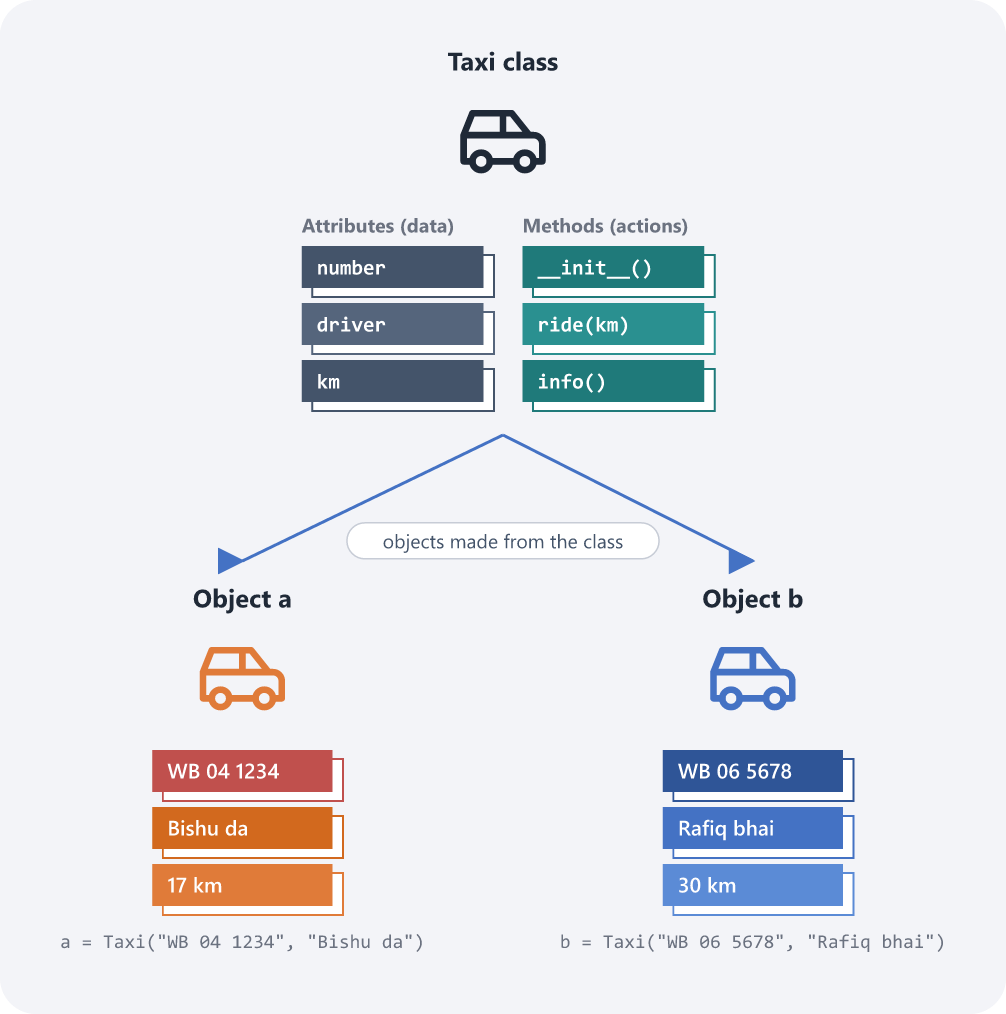

- At the top is the **class** (the design). It lists the **attributes** (data) and the **methods** (actions).
- The arrows show two **objects** made from the class: `a` and `b`.
- Both objects have the same attributes, but each one has **its own values**.

## **Concept of self**
**self** means "**this particular object**".

When we write `a.ride(12)`, Python actually runs `Taxi.ride(a, 12)`. So inside the method, `self` is the object `a`. That is how the method knows **which** taxi's km to change.

In [5]:
Taxi.ride(a, 3)        # Same as a.ride(3)
print(a.km)

# self and the object are the same thing in memory
class Demo:
    def __init__(self):
        print("Address of self  :", id(self))

obj = Demo()
print("Address of object:", id(obj))

WB 04 1234 drove 3 km
20
Address of self  : 2706327616544
Address of object: 2706327616544


Both addresses are the same. This shows that `self` is the object itself.

## **Seeing the Data Inside an Object**

In [6]:
print(a.__dict__)
print(b.__dict__)

{'number': 'WB 04 1234', 'driver': 'Bishu da', 'km': 20}
{'number': 'WB 06 5678', 'driver': 'Rafiq bhai', 'km': 30}


## **Example from Remote Sensing: A Satellite Image Class**
Let us make a class for a satellite image (scene). It stores information about the image and can tell us if the image is good to use.

In [7]:
class SatelliteImage:
    def __init__(self, satellite, date, cloud_cover, resolution_m):
        self.satellite = satellite
        self.date = date
        self.cloud_cover = cloud_cover
        self.resolution_m = resolution_m

    def is_usable(self, max_cloud=20):
        return self.cloud_cover <= max_cloud

    def pixel_area(self):
        return self.resolution_m ** 2

    def summary(self):
        status = "Usable" if self.is_usable() else "Too cloudy"
        return f"{self.satellite} ({self.date}) - cloud {self.cloud_cover}% - {status}"

images = [
    SatelliteImage("Sentinel-2", "2024-01-20", 3, 10),
    SatelliteImage("Landsat 8", "2024-07-11", 78, 30),
    SatelliteImage("Sentinel-2", "2024-11-06", 12, 10),
]

for img in images:
    print(img.summary())

print("One Landsat pixel covers", images[1].pixel_area(), "square metre")

Sentinel-2 (2024-01-20) - cloud 3% - Usable
Landsat 8 (2024-07-11) - cloud 78% - Too cloudy
Sentinel-2 (2024-11-06) - cloud 12% - Usable
One Landsat pixel covers 900 square metre


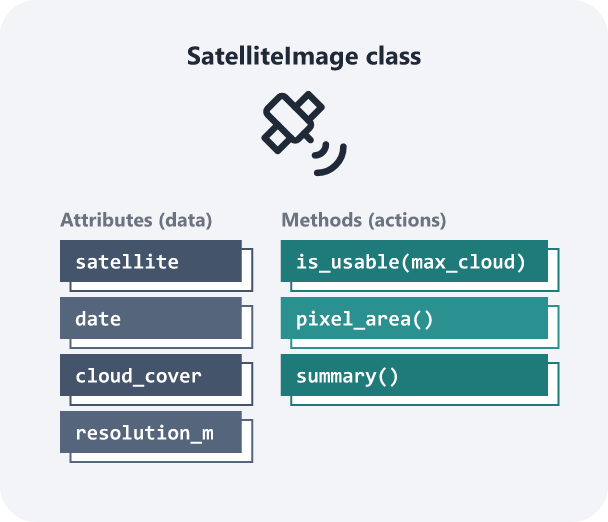

## **Methods vs Functions**
- A **function** is independent. It is not attached to any object. Example: `len(L)`.
- A **method** belongs to a class and is called on an object with a dot. Example: `L.append(4)`.

In [8]:
L = [1, 2, 3]
print(len(L))       # Function: it is outside the list class
L.append(4)         # Method: it is inside the list class
print(L)

3
[1, 2, 3, 4]


## **Why Use OOP?**
1. **Organized code:** Data and actions stay together.
2. **Reusable:** One class can make any number of objects.
3. **Easy to model real life:** Taxis, students, bank accounts, satellite images.
4. **Easy to extend:** We can build new classes from old ones (Inheritance, Day 45).

## **Practice Problem: A Student Class**

In [9]:
class Student:
    def __init__(self, name, school, marks):
        self.name = name
        self.school = school
        self.marks = marks         # Dictionary of subject: marks

    def total(self):
        return sum(self.marks.values())

    def percentage(self):
        return round(self.total() / len(self.marks), 2)

    def best_subject(self):
        return max(self.marks, key=self.marks.get)

s = Student("Ritika", "Midnapore Girls' High School", {"Bengali": 88, "Maths": 95, "Geography": 79})
print(s.name, "| Total:", s.total(), "| Percentage:", s.percentage(), "| Best:", s.best_subject())

Ritika | Total: 262 | Percentage: 87.33 | Best: Maths


In [10]:
# Quick question
# Guess the output of this code cell
# class A:
#     def __init__(self):
#         self.x = 5
# p = A()
# q = A()
# p.x = 10
# print(p.x, q.x)